FATURAMENTO TOTAL :

Nesta célula irei verificar e tratar alguns dados, bem como importar bibliotecas a serem usadas nas próximas células.

In [38]:

import matplotlib.pyplot as plt
import pandas as pd
from matplotlib.pyplot import xticks
from numpy.ma.core import angle

url = "vendas.csv"

df_url = pd.read_csv(url, sep=';')
df_url['cidade_cliente'] = df_url['cidade_cliente'].fillna('Não Informada')
df_tratado = df_url.drop_duplicates().copy()
df_tratado['quantidade'] = df_tratado['quantidade'].abs()
nomes_vendedores = df_url.groupby("nome_vendedor").size()
nome_categorias = df_url.groupby("categoria_produto").size()
print ("-"*50)
print (nome_categorias)
print ("-"*50)
df_tratado['categoria_limpa'] = df_tratado['categoria_produto'].replace({
    'Informatica': 'Informática',
    'Eletronicos': 'Eletrônicos'
})
df_tratado['data_venda'] = pd.to_datetime(df_tratado['data_venda'], errors='coerce')
df_tratado = df_tratado.dropna(subset=['data_venda']).copy()
print (nomes_vendedores)
print ("-"*50)



--------------------------------------------------
categoria_produto
Acessórios      9941
Eletronicos       47
Eletrônicos    13335
Informatica       62
Informática    19915
Áudio           6700
dtype: int64
--------------------------------------------------
nome_vendedor
Ana Silva         3348
Bruno Costa       3236
Carlos Eduardo    3479
Diana Souza       3298
Eduardo Lima      3237
Fernanda Alves    3418
Gabriel Gomes     3328
Helena Rocha      3214
Igor Santos       3225
Julia Martins     3484
Kauan Vieira      3419
Larissa Mendes    3304
Marcos Paulo      3420
Natália Pires     3203
Otávio Borges     3387
dtype: int64
--------------------------------------------------


Calculei o faturamento bruto por item (quantidade X preço) e o líquido por categoria para entender a situação atual das vendas.

------------- RESUMO DE FATURAMENTO (VENDAS CONCLUÍDAS) -------------
		Faturamento Total Bruto:   R$ 117,627,401.80
		Total de Descontos:        R$ 7,325,877.70 (6.23%)
		Faturamento Total Líquido: R$ 110,301,524.10
----------------------------------------------------------------------


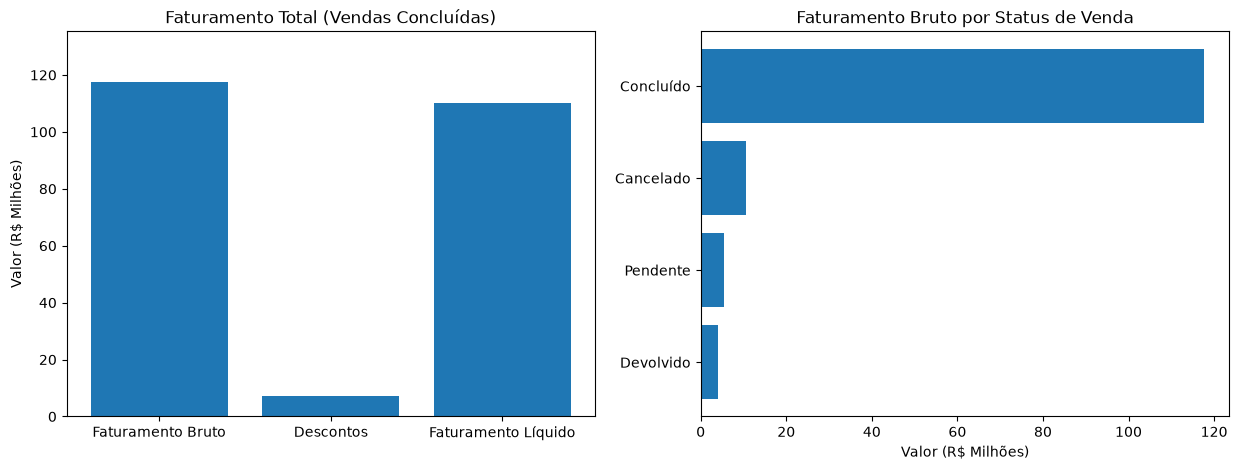

In [39]:
df_tratado['faturamento_bruto'] = df_tratado['quantidade'] * df_tratado['preco_unitario']
df_vendas_concluidas = df_tratado[df_tratado['status_venda'] == 'Concluído']

#calculando as categorias bruto, líquido e descontos
faturamento_total_bruto = df_vendas_concluidas['faturamento_bruto'].sum()
total_descontos = df_vendas_concluidas['desconto'].sum()
faturamento_total_liquido = df_vendas_concluidas['valor_total'].sum()

#criando nova variavel p ver a MÉDIA de descontos que estão aplicando nas vendas CONCLUÍDAS e multiplicando por 100 para ter a %
taxa_desconto = (total_descontos / faturamento_total_bruto) * 100

#exibindo os dados das vendas
print("-" * 13, "RESUMO DE FATURAMENTO (VENDAS CONCLUÍDAS)", "-" * 13)
print(f"\t\tFaturamento Total Bruto:   R$ {faturamento_total_bruto:,.2f}")
print(f"\t\tTotal de Descontos:        R$ {total_descontos:,.2f} ({taxa_desconto:.2f}%)")
print(f"\t\tFaturamento Total Líquido: R$ {faturamento_total_liquido:,.2f}")
print("-"*70)

#criando 2 gráficos com subplots
fig, axs = plt.subplots(1, 2, figsize=(15, 5))

# inserindo nos gráficos as info ( dividido por 1mm pra formatar o valor.)
categorias = ['Faturamento Bruto', 'Descontos', 'Faturamento Líquido']
valores_milhoes = [
    faturamento_total_bruto / 1000000,
    total_descontos / 1000000,
    faturamento_total_liquido / 1000000
]

barras = axs[0].bar(categorias, valores_milhoes)
axs[0].set_title('Faturamento Total (Vendas Concluídas)')
axs[0].set_ylabel('Valor (R$ Milhões)')
axs[0].set_ylim(0, max(valores_milhoes) * 1.15)


resumo_status = df_tratado.groupby('status_venda')['faturamento_bruto'].sum().sort_values(ascending=True)
axs[1].barh(resumo_status.index, resumo_status.values / 1000000 )
axs[1].set_title('Faturamento Bruto por Status de Venda')
axs[1].set_xlabel('Valor (R$ Milhões)')



plt.show()

nesta célula calculei a quatidade de itens dos 10 mais vendidos, pra facilitar inclui as informações em um gráfico de barra.


               nome_produto  quantidade
0      Teclado Mecânico RGB        4389
1            Monitor 27" 4K        4330
2      Smartphone Premium X        4279
3       Smartphone Básico Y        4266
4       Mouse Gamer 10k DPI        4262
5        Notebook Estudante        4221
6     Caixa de Som Portátil        4218
7        Notebook Ultra Pro        4179
8           Smart TV 55" 4K        4177
9  Fone de Ouvido Bluetooth        4172


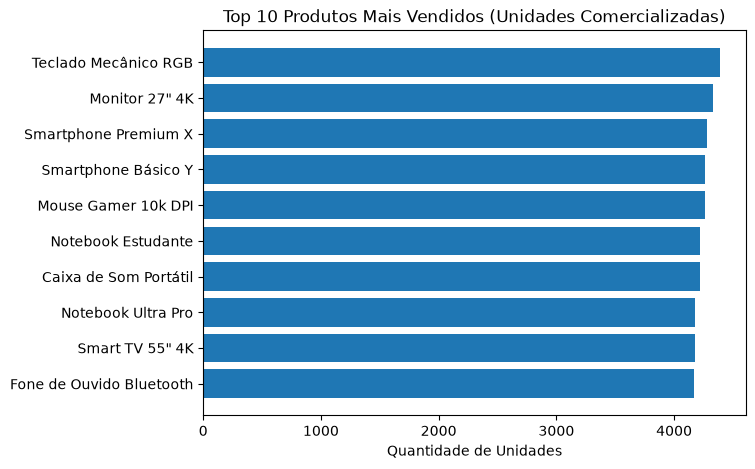

In [40]:
df_concluido = df_tratado[df_tratado['status_venda'] == 'Concluído']


#agrupando os produtos com groupby e somando as quantidades pra gerar o relatório das top 10
top10_produtos = (
    df_concluido.groupby('nome_produto')['quantidade'].sum().sort_values(ascending=False).head(10).reset_index()
)
print(top10_produtos)

#criando o gráfico e inserindo os dados

plt.figure(figsize=(7, 5))
dados_plot = top10_produtos.sort_values('quantidade', ascending=True)

plt.barh(dados_plot['nome_produto'], dados_plot['quantidade'])
plt.title('Top 10 Produtos Mais Vendidos (Unidades Comercializadas)')
plt.xlabel('Quantidade de Unidades')
plt.savefig('assets/top10_produtos.png', bbox_inches='tight', dpi=300)
plt.show()




Nesta célula assim como a anterior somei o faturamento, porém dessa vez dividido entre CATEGORIAS invés de PRODUTO para entender melhor as categorias mais vendidas.

------------- RESUMO DE FATURAMENTO CATEGORIAS -------------
  categoria_limpa  valor_total  porcentagem participacao %
0     Informática  59324153.84                   53.783621
1     Eletrônicos  43549096.99                   39.481863
2      Acessórios   4477086.49                    4.058953
3           Áudio   2951186.78                    2.675563
------------------------------------------------------------


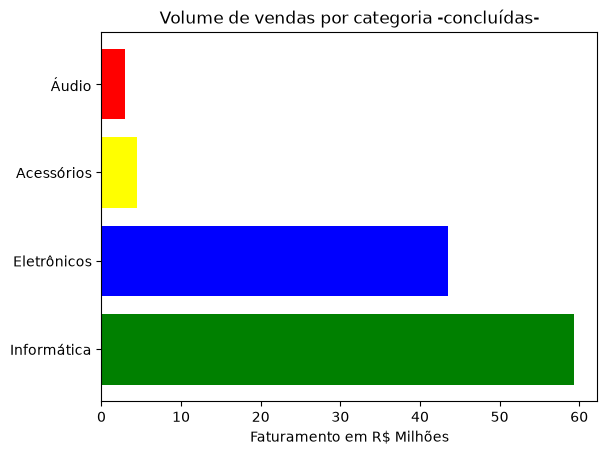

In [41]:
#filtrando e calculando usando groupby.
df_concluido = df_tratado[df_tratado['status_venda'] == 'Concluído']
faturamento_categoria = (
    df_concluido.groupby('categoria_limpa')['valor_total'].sum().sort_values(ascending=False).reset_index()
)
faturamento_categoria['porcentagem participacao %'] = (faturamento_categoria['valor_total'] / faturamento_categoria['valor_total'].sum()) * 100 # mesma coisa para tirar a % dos 100% vendidos do valor total de CONCLUÍDOS.
print("-" * 13, "RESUMO DE FATURAMENTO CATEGORIAS", "-" * 13)
print(f"{faturamento_categoria}")
print("-"*60)

#criando e adicionando dados
plt.figure()
barras = plt.barh(faturamento_categoria['categoria_limpa'], faturamento_categoria['valor_total'] / 1000000, color=['g', 'b', 'yellow', 'red'])
plt.title('Volume de vendas por categoria -concluídas-')
plt.xlabel('Faturamento em R$ Milhões')
plt.savefig('assets/faturamento_categoria.png', bbox_inches='tight', dpi=300)
plt.show()

Nesta célula calculei os valores de vendas anuais e a diferença do ano anterior (2021 sem referência anterior, é a base)  por ser um código simples não comentei.

In [42]:
df_concluido = df_tratado[df_tratado['status_venda'] == 'Concluído']
df_concluido['ano'] = df_concluido['data_venda'].dt.year

soma_anual = df_concluido.groupby('ano')['valor_total'].sum()
v2021 = soma_anual[2021]
v2022 = soma_anual[2022]
v2023 = soma_anual[2023]

dif_2022 = v2022 - v2021
pct_2022 = (dif_2022 / v2021) * 100
dif_2023 = v2023 - v2022
pct_2023 = (dif_2023 / v2022) * 100
print("-"*50)
print("Faturamento total entre os anos e as diferenças em relação ao ano anterior.")
print(f"2021: R$ {v2021:,.2f}")
print(f"2022: R$ {v2022:,.2f} | Diferença: R$ {dif_2022:,.2f} ({pct_2022:.2f}%)")
print(f"2023: R$ {v2023:,.2f} | Diferença: R$ {dif_2023:,.2f} ({pct_2023:.2f}%)")
print("-"*50)





--------------------------------------------------
Faturamento total entre os anos e as diferenças em relação ao ano anterior.
2021: R$ 36,814,175.96
2022: R$ 36,179,139.79 | Diferença: R$ -635,036.17 (-1.72%)
2023: R$ 37,308,208.35 | Diferença: R$ 1,129,068.56 (3.12%)
--------------------------------------------------


In [43]:
df_concluido = df_tratado[df_tratado['status_venda'] == 'Concluído'].copy()
df_concluido['mes_ano'] = df_concluido['data_venda'].astype(str).str.slice(0, 7)

evolucao = df_concluido.groupby('mes_ano')['valor_total'].sum().reset_index()

# Divide só a coluna de valor por 1 milhão e arredonda
evolucao['valor_total'] = (evolucao['valor_total'] / 1000000)

print(evolucao.sort_values('valor_total', ascending=False))

    mes_ano  valor_total
11  2021-12     4.179356
10  2021-11     3.780032
22  2022-11     3.709859
23  2022-12     3.689253
31  2023-08     3.425270
35  2023-12     3.395337
24  2023-01     3.354019
33  2023-10     3.240569
28  2023-05     3.236757
34  2023-11     3.234472
27  2023-04     3.133511
0   2021-01     3.125678
12  2022-01     3.113142
20  2022-09     3.089908
19  2022-08     3.088617
30  2023-07     3.082527
7   2021-08     3.081047
6   2021-07     3.049080
16  2022-05     3.042267
9   2021-10     3.012054
14  2022-03     2.979571
25  2023-02     2.975020
17  2022-06     2.962035
2   2021-03     2.960942
4   2021-05     2.957966
8   2021-09     2.919834
29  2023-06     2.851497
15  2022-04     2.765732
3   2021-04     2.728536
32  2023-09     2.716136
26  2023-03     2.663093
5   2021-06     2.662660
13  2022-02     2.632671
21  2022-10     2.619553
18  2022-07     2.486531
1   2021-02     2.356991


Nesta célula  irei explorar a evolução durante os meses para compreender melhor a sazonalidade de vendas durante o períodos de jan/21 e dez/23 para tomar melhores decisões de ação. a princípio tinha feito um gráfico apenas com os 3 anos, retornei no site do matplotlib e aprendi no " simple plot " a aplicação de um gráfico mais didático onde coloquei os 3 anos de forma separada, no eixo X os meses do ano e Y os valores e assim ficar mais didático a visualização da diferença mês a mês.

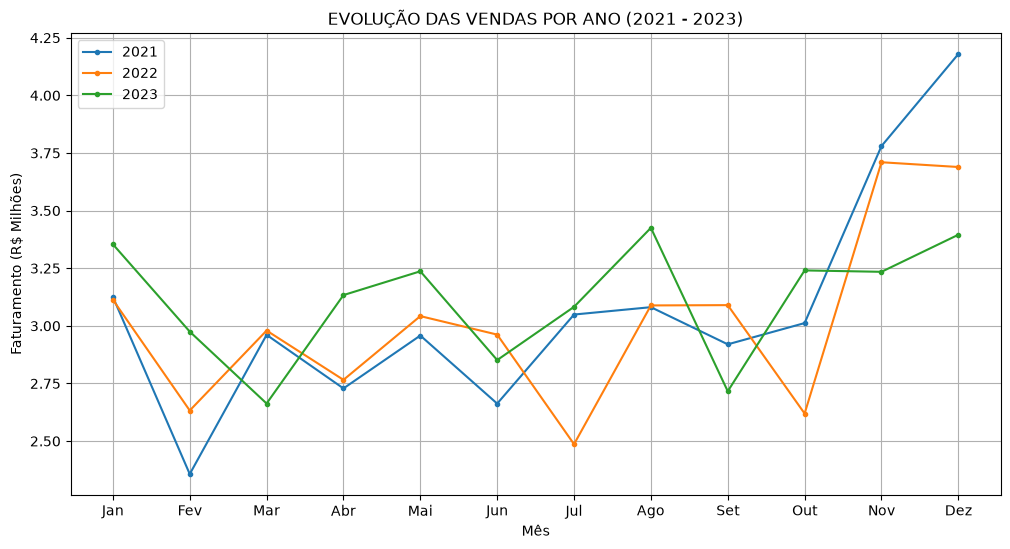

In [44]:
# filtrar datas e somar o faturamento por ano e mês
df_concluido = df_tratado[df_tratado['status_venda'] == 'Concluído']
df_concluido['ano'] = df_concluido['data_venda'].dt.year
df_concluido['mes'] = df_concluido['data_venda'].dt.month

evolucao = df_concluido.groupby(['ano', 'mes'])['valor_total'].sum().reset_index()

#separando os dados de cada ano
meses = ['Jan', 'Fev', 'Mar', 'Abr', 'Mai', 'Jun', 'Jul', 'Ago', 'Set', 'Out', 'Nov', 'Dez']
v2021 = evolucao[evolucao['ano'] == 2021]['valor_total'] / 1000000
v2022 = evolucao[evolucao['ano'] == 2022]['valor_total'] / 1000000
v2023 = evolucao[evolucao['ano'] == 2023]['valor_total'] / 1000000

# criando e adicionando informações no gráfico
fig, ax = plt.subplots(figsize=(12, 6))
ax.plot(meses, v2021, marker='.', label='2021')
ax.plot(meses, v2022, marker='.', label='2022')
ax.plot(meses, v2023, marker='.', label='2023')

ax.set_xlabel('Mês')
ax.set_ylabel('Faturamento (R$ Milhões)')
ax.set_title('EVOLUÇÃO DAS VENDAS POR ANO (2021 - 2023)')
ax.legend()
ax.grid()

plt.savefig('assets/evolucao_vendas_ano.png', bbox_inches='tight', dpi=300)
plt.show()

proxima celula veremos o desempenho dos 5 melhores vendedores e seus respectivos ticket médio.

------------- TOP 5 VENDEDORES (VENDAS CONCLUÍDAS) -------------
    nome_vendedor  faturamento_liquido  ticket_medio  participacao_%
0  Carlos Eduardo           8071926.26   2726.081142        7.318055
1  Fernanda Alves           7862972.91   2673.571204        7.128617
2   Otávio Borges           7670842.79   2706.719404        6.954430
3     Diana Souza           7532880.12   2662.735992        6.829353
4   Julia Martins           7441960.63   2564.424752        6.746925
----------------------------------------------------------------


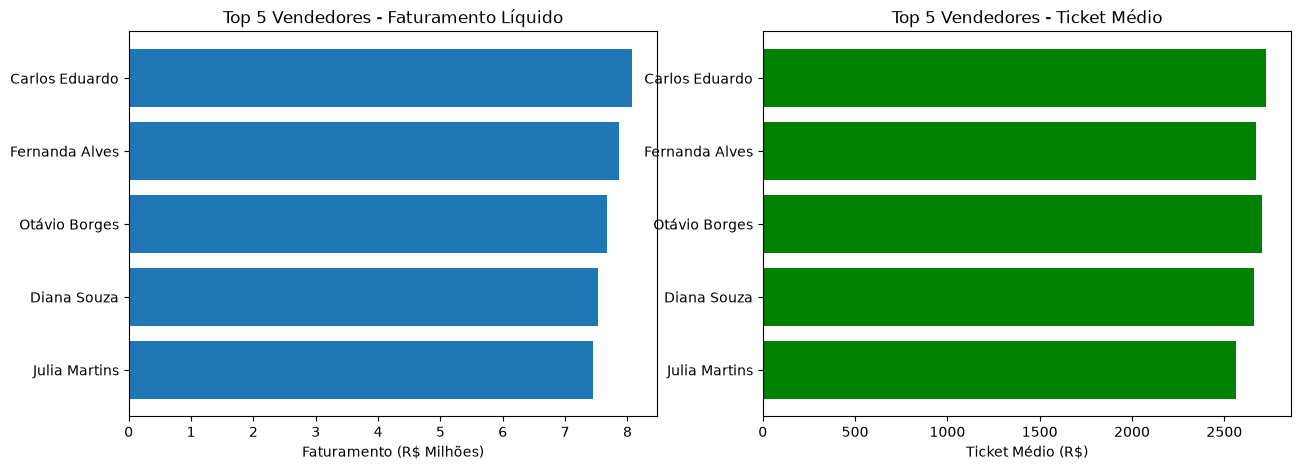

In [45]:
df_concluido = df_tratado[df_tratado['status_venda'] == 'Concluído']

faturamento = df_concluido.groupby('nome_vendedor')['valor_total'].sum().sort_values(ascending=False).head(5)
ticket_medio = df_concluido.groupby('nome_vendedor')['valor_total'].mean()

top5_vendedores = pd.DataFrame({
    'faturamento_liquido': faturamento,
    'ticket_medio': ticket_medio[faturamento.index]
}).reset_index()

top5_vendedores['participacao_%'] = (top5_vendedores['faturamento_liquido'] / df_concluido['valor_total'].sum()) * 100

print("-" * 13, "TOP 5 VENDEDORES (VENDAS CONCLUÍDAS)", "-" * 13)
print(top5_vendedores)
print("-" * 64)

fig, axs = plt.subplots(1, 2, figsize=(15, 5))
dados_plot = top5_vendedores.sort_values('faturamento_liquido', ascending=True)

axs[0].barh(dados_plot['nome_vendedor'], dados_plot['faturamento_liquido'] / 1000000)
axs[0].set_title('Top 5 Vendedores - Faturamento Líquido')
axs[0].set_xlabel('Faturamento (R$ Milhões)')

axs[1].barh(dados_plot['nome_vendedor'], dados_plot['ticket_medio'], color='green')
axs[1].set_title('Top 5 Vendedores - Ticket Médio')
axs[1].set_xlabel('Ticket Médio (R$)')

plt.show()

formas de pagamento e participações no faturamento total.

------------- PREFERÊNCIAS DE PAGAMENTO (CONCLUÍDAS) -------------
     forma_pagamento  total_transacoes  participacao_%
0  Cartão de Crédito             10842       25.628782
1                PIX             10695       25.281297
2             Boleto             10560       24.962179
3   Cartão de Débito             10207       24.127742
------------------------------------------------------------------


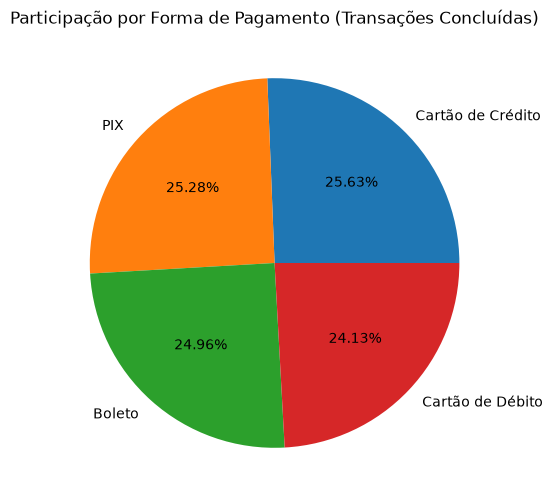

In [46]:
df_concluido = df_tratado[df_tratado['status_venda'] == 'Concluído']

pagamentos = df_concluido.groupby('forma_pagamento').size().sort_values(ascending=False).reset_index(name='total_transacoes')
pagamentos['participacao_%'] = (pagamentos['total_transacoes'] / pagamentos['total_transacoes'].sum()) * 100

print("-" * 13, "PREFERÊNCIAS DE PAGAMENTO (CONCLUÍDAS)", "-" * 13)
print(pagamentos)
print("-" * 66)

plt.figure(figsize=(8, 6))
plt.pie(
    pagamentos['total_transacoes'],
    labels=pagamentos['forma_pagamento'],
    autopct='%1.2f%%'
)
plt.title('Participação por Forma de Pagamento (Transações Concluídas)')
plt.show()

Divisão dos estados para região usando replace, e então com 4 regiões definidas calculando o total de todos os estados daquela região para entender as vendas concluídas/região.

------------- FATURAMENTO POR ESTADO (UF) -------------
  estado_cliente  valor_total  participacao_%
0             PR  11594186.46       10.511357
1             SC  11302055.61       10.246509
2             BA  11112235.78       10.074417
3             MG  11088729.25       10.053106
4             SP  11080298.02       10.045462
5             DF  11012136.09        9.983666
6             RJ  10993900.48        9.967134
7             PE  10928214.39        9.907582
8             GO  10925387.36        9.905019
9             RS  10264380.66        9.305747
-------------------------------------------------------
------------- FATURAMENTO POR REGIÃO -------------
         regiao  valor_total  participacao_%
0       Sudeste  33162927.75       30.065702
1           Sul  33160622.73       30.063612
2      Nordeste  22040450.17       19.982000
3  Centro-Oeste  21937523.45       19.888686
--------------------------------------------------


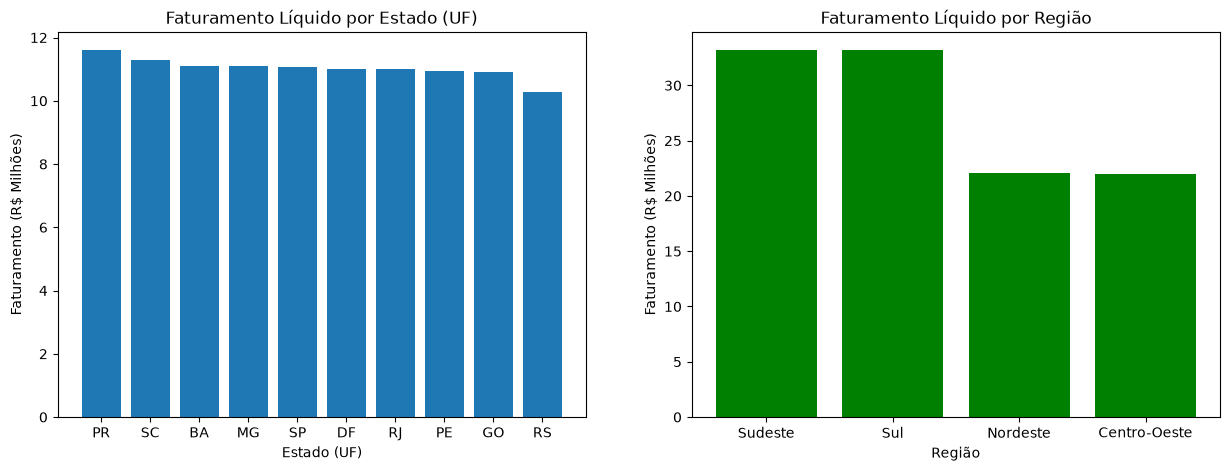

In [47]:
df_concluido = df_tratado[df_tratado['status_venda'] == 'Concluído']

estados = df_concluido.groupby('estado_cliente')['valor_total'].sum().sort_values(ascending=False).reset_index()
estados['participacao_%'] = (estados['valor_total'] / estados['valor_total'].sum()) * 100

regiao = df_concluido['estado_cliente'].replace({
    'PR': 'Sul', 'SC': 'Sul', 'RS': 'Sul',
    'DF': 'Centro-Oeste', 'GO': 'Centro-Oeste',
    'BA': 'Nordeste', 'PE': 'Nordeste',
    'MG': 'Sudeste', 'RJ': 'Sudeste', 'SP': 'Sudeste'
})
regioes = df_concluido.groupby(regiao)['valor_total'].sum().sort_values(ascending=False).reset_index()
regioes.columns = ['regiao', 'valor_total']
regioes['participacao_%'] = (regioes['valor_total'] / regioes['valor_total'].sum()) * 100

print("-" * 13, "FATURAMENTO POR ESTADO (UF)", "-" * 13)
print(estados)
print("-" * 55)
print("-" * 13, "FATURAMENTO POR REGIÃO", "-" * 13)
print(regioes)
print("-" * 50)

fig, axs = plt.subplots(1, 2, figsize=(15, 5))

axs[0].bar(estados['estado_cliente'], estados['valor_total'] / 1000000)
axs[0].set_title('Faturamento Líquido por Estado (UF)')
axs[0].set_xlabel('Estado (UF)')
axs[0].set_ylabel('Faturamento (R$ Milhões)')

axs[1].bar(regioes['regiao'], regioes['valor_total'] / 1000000, color='green')
axs[1].set_title('Faturamento Líquido por Região')
axs[1].set_xlabel('Região')
axs[1].set_ylabel('Faturamento (R$ Milhões)')

plt.show()